AttribDict({'seismometer_gain': 1.0, 'digitizer_gain': 1.0, 'poles': [(-0.148-0.148j), (-0.148+0.148j), (-1130.97+0j), (-1005.3+0j), (-502.65+0j)], 'zeros': [0j, 0j, 0j], 'sensitivity': 1.0, 'gain': 7.16e+17})


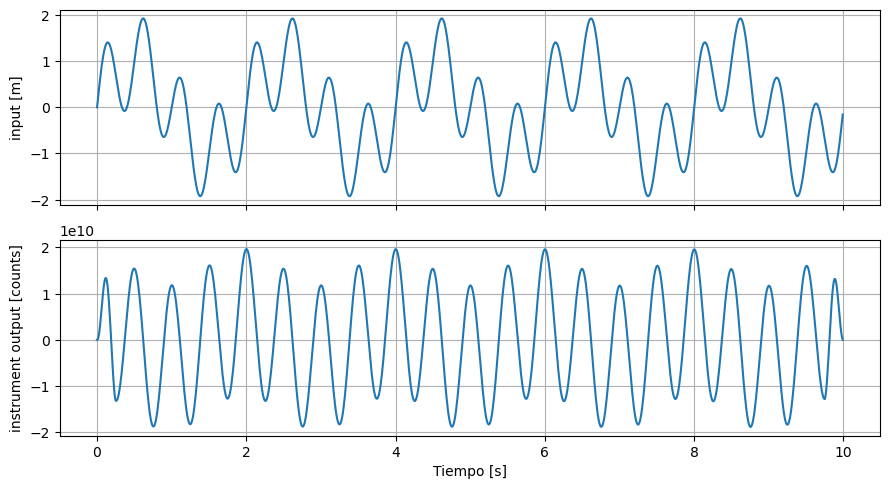

In [1]:
# script para generar una funcion de prueba y luego aplicar la respuesta instrumental
import numpy as np
import matplotlib.pyplot as plt
from obspy import Trace, UTCDateTime
from obspy.io.sac.sacpz import attach_paz

# estos entradas son las frecuencas de los dos senos de la funcion de prueba
f1 = 2.0          # Hz, sine #1
f2 = 0.5          # Hz, sine #2
dt = 0.01         # s  (Fs = 1/dt)
npts = 1000        # numero de muestras
pz_file = "40T.pz.txt"  # SACPZ file que debe estar en el directorio

# generar test function input
t = np.arange(npts) * dt
ut = np.sin(2*np.pi*f1*t) + np.sin(2*np.pi*f2*t)      # arbitrary amplitude

tr = Trace(ut)
tr.stats.sampling_rate = 1.0/dt
tr.stats.starttime = UTCDateTime(0)

# leer los polos y ceros y generar la informacion de los polos y ceros
attach_paz(tr, paz_file=pz_file)     # generar tr.stats.paz desde 40T.pz
paz = tr.stats.paz                   # poles, zeros, ganancia
print(paz) 

# generar la traza del instrumento suponiendo que la entrada es desplazamiento del suelo
tr_instr = tr.copy().simulate(paz_simulate=paz) 

#alternativamente se puede suponer que la entrada es velocidad o aceleracion del suelo
#tr_instr = tr.copy().integrate().simulate(paz_simulate=tr.stats.paz)
#tr_instr = tr.copy().integrate().integrate().simulate(paz_simulate=tr.stats.paz)

# generar grafico de entrada y salida
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(9,5))
tt = tr.times(reftime=tr.stats.starttime)

# recuerde cambiar las unidades de input, dependiendo si son m, m/s o m/s/s
ax1.plot(tt, tr.data);      ax1.set_ylabel("input [m]")
ax2.plot(tt, tr_instr.data); ax2.set_ylabel("instrument output [counts]")
ax2.set_xlabel("Tiempo [s]")
ax1.grid(True); ax2.grid(True); fig.tight_layout() 
# guardar con un cierto nombre
plt.savefig('inputoutput_uaz.png')
plt.show()



         network: XJ
         station: MURT
        location: 
         channel: HHZ
       starttime: 2004-01-25T11:54:45.300000Z
         endtime: 2004-01-25T11:56:35.300000Z
   sampling_rate: 100.0
           delta: 0.01
            npts: 11001
           calib: 1254690000.0
         _format: SAC
             sac: AttribDict({'delta': 0.01, 'depmin': -1973.6868, 'depmax': 1968.1381, 'scale': 1254690000.0, 'b': 695.0, 'e': 805.0, 'o': 0.0, 'internal0': 2.0, 't1': 748.06, 't4': 1365.58, 'stla': -46.455, 'stlo': -72.68, 'stel': 260.0, 'stdp': 0.0, 'evla': -16.8452, 'evlo': -174.1695, 'evdp': 129.0, 'user0': 0.0089988755, 'user7': 6.2, 'dist': 9518.976, 'az': 137.19742, 'baz': 250.24997, 'gcarc': 85.62884, 'depmen': 0.1617779, 'cmpaz': 0.0, 'cmpinc': 0.0, 'nzyear': 2004, 'nzjday': 25, 'nzhour': 11, 'nzmin': 43, 'nzsec': 10, 'nzmsec': 300, 'nvhdr': 6, 'norid': 0, 'nevid': 0, 'npts': 11001, 'iftype': 1, 'iztype': 11, 'leven': 1, 'lpspol': 0, 'lovrok': 1, 'lcalda': 1, 'unused23': 0, 'kstnm

array([False, False, False, ..., False, False, False])

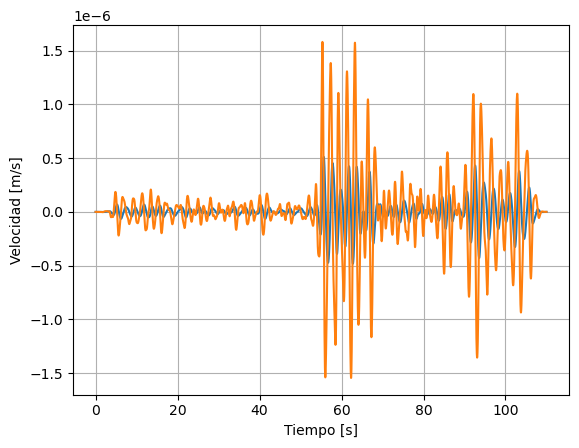

In [14]:
from obspy import read
import matplotlib.pyplot as plt
from obspy import Trace, UTCDateTime
from obspy.io.sac.sacpz import attach_paz
pz_file = "40T.pz.txt"
#leer traza
tr = read('murta.sac')[0]
#ver los metadatos
print(tr.stats)
#agregar pz a la traza
attach_paz(tr, paz_file=pz_file)
paz = tr.stats.paz
# poles, zeros, ganancia

#Filtrar la traza con un filtro pasa banda
pre_filt = (0.01, 0.03, 50, 100) #frecuencias de corte en Hz

# Quitar instrumento a desplazamiento em metros
tr_u = tr.copy().simulate(paz_remove=paz, pre_filt=pre_filt)
# cambiar de desplazamiento a velocidad
tr_v = tr_u.copy()
tr_v = tr_v.differentiate()
#graficar la traza usando matplotlib

t_u = tr_u.times()
plt.plot(t_u, tr_u.data)
plt.xlabel("Tiempo [s]"); plt.ylabel("Desplazamiento [m]"); plt.grid(True)
plt.savefig("desplazamiento.png", dpi=300, bbox_inches='tight')

t_v = tr_v.times()
plt.plot(t_v, tr_v.data)
plt.xlabel("Tiempo [s]"); plt.ylabel("Velocidad [m/s]"); plt.grid(True)
plt.savefig("velocidad.png", dpi=300, bbox_inches='tight')

v = tr_u.data == tr_v.data
display (v)